In [ ]:

#cell 1

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import random

SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)
print("Smart Waste Classification project is ready!")


TensorFlow version: 2.21.0
GPU available: True
Smart Waste Classification project is ready!


In [ ]:

#cell 2

import os
import urllib.request
import zipfile

DATASET_URL = "https://github.com/garythung/trashnet/raw/master/data/dataset-resized.zip"
ZIP_PATH = "/content/waste_dataset.zip"
EXTRACT_PATH = "/content/waste_data"

if not os.path.exists(os.path.join(EXTRACT_PATH, "dataset-resized")):
    print("Downloading waste classification dataset...")
    urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)

    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)

print("Dataset setup completed!")
print("Dataset location:", EXTRACT_PATH)
print("Available files:", os.listdir(EXTRACT_PATH))


Extracting dataset...
Dataset setup completed!
Dataset location: /content/waste_data
Available files: ['__MACOSX', 'dataset-resized']


In [ ]:

#cell 3

import os

DATASET_DIR = "/content/waste_data/dataset-resized"

if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}. "
        "Please check whether Cell 2 completed successfully."
    )

categories = sorted([
    folder for folder in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, folder))
])

print("Number of categories:", len(categories))
print("\nWaste categories and image counts:")

for category in categories:
    folder_path = os.path.join(DATASET_DIR, category)
    image_count = sum(
        1 for filename in os.listdir(folder_path)
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    )
    print(f"{category}: {image_count} images")

print("\nDataset verification completed!")


Number of categories: 6

Waste categories and image counts:
cardboard: 403 images
glass: 501 images
metal: 410 images
paper: 594 images
plastic: 482 images
trash: 137 images

Dataset verification completed!


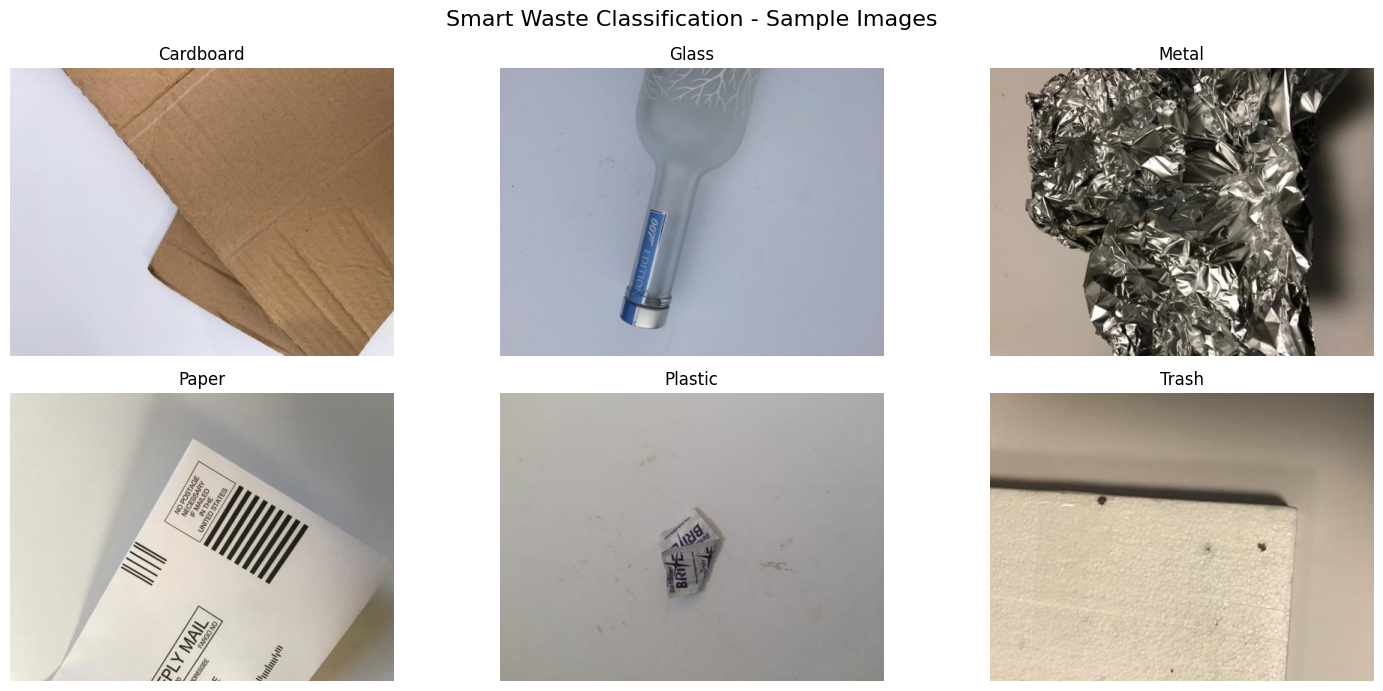

Sample image visualization completed!


In [ ]:

#cell 4

import matplotlib.pyplot as plt
from PIL import Image
import os
import random

plt.figure(figsize=(15, 7))

for index, category in enumerate(categories):
    folder_path = os.path.join(DATASET_DIR, category)

    image_files = [
        file for file in os.listdir(folder_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    if not image_files:
        continue

    image_path = os.path.join(folder_path, random.choice(image_files))
    image = Image.open(image_path).convert("RGB")

    plt.subplot(2, 3, index + 1)
    plt.imshow(image)
    plt.title(category.capitalize())
    plt.axis("off")

plt.suptitle("Smart Waste Classification - Sample Images", fontsize=16)
plt.tight_layout()
plt.show()

print("Sample image visualization completed!")


In [ ]:

#cell 5

import os
import shutil
import random

random.seed(42)

SPLIT_DIR = "/content/waste_split"
TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
VAL_DIR = os.path.join(SPLIT_DIR, "validation")
TEST_DIR = os.path.join(SPLIT_DIR, "test")

# Create a fresh split directory
if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    os.makedirs(split_dir, exist_ok=True)

for category in categories:
    source_dir = os.path.join(DATASET_DIR, category)

    images = [
        file for file in os.listdir(source_dir)
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    random.shuffle(images)

    total = len(images)
    train_end = int(total * 0.70)
    val_end = train_end + int(total * 0.15)

    split_files = {
        TRAIN_DIR: images[:train_end],
        VAL_DIR: images[train_end:val_end],
        TEST_DIR: images[val_end:]
    }

    for destination_dir, filenames in split_files.items():
        category_dir = os.path.join(destination_dir, category)
        os.makedirs(category_dir, exist_ok=True)

        for filename in filenames:
            shutil.copy2(
                os.path.join(source_dir, filename),
                os.path.join(category_dir, filename)
            )

print("Dataset splitting completed!\n")

for split_name, split_dir in [
    ("Training", TRAIN_DIR),
    ("Validation", VAL_DIR),
    ("Testing", TEST_DIR)
]:
    total_images = sum(
        len([
            f for f in os.listdir(os.path.join(split_dir, category))
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ])
        for category in categories
    )
    print(f"{split_name} images: {total_images}")

print("\nAll datasets are ready!")


Dataset splitting completed!

Training images: 1766
Validation images: 377
Testing images: 384

All datasets are ready!


In [ ]:

#cell 6

import tensorflow as tf
import os

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("\nClass names:", class_names)
print("Number of classes:", len(class_names))
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())
print("\nImage preprocessing completed!")


Found 1766 files belonging to 6 classes.
Found 377 files belonging to 6 classes.
Found 384 files belonging to 6 classes.

Class names: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Number of classes: 6
Training batches: 56
Validation batches: 12
Testing batches: 12

Image preprocessing completed!


In [ ]:

#cell 7

import tensorflow as tf
from tensorflow.keras import layers, models

# Data augmentation to improve generalization
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10)
], name="data_augmentation")

# Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers for initial training
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = models.Model(inputs, outputs, name="SmartWasteClassifier")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()
print("\nMobileNetV2 model built successfully!")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "SmartWasteClassifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


MobileNetV2 model built successfully!


In [ ]:

#cell 8

import os
import tensorflow as tf

MODEL_DIR = "/content/smart_waste_models"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR, "best_smart_waste_model.keras"
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Training callbacks configured!")
print("Best model will be saved at:", BEST_MODEL_PATH)
print("Early stopping and learning-rate reduction are enabled.")


Training callbacks configured!
Best model will be saved at: /content/smart_waste_models/best_smart_waste_model.keras
Early stopping and learning-rate reduction are enabled.


In [ ]:

#cell 9

EPOCHS = 8

print("Starting Smart Waste Classification training...")

train_images = sum(
    len(os.listdir(os.path.join(TRAIN_DIR, category)))
    for category in class_names
)

validation_images = sum(
    len(os.listdir(os.path.join(VAL_DIR, category)))
    for category in class_names
)

print("Training images:", train_images)
print("Validation images:", validation_images)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

print("\nInitial training completed!")
print("Best model path:", BEST_MODEL_PATH)
print("Model file exists:", os.path.exists(BEST_MODEL_PATH))


Starting Smart Waste Classification training...
Training images: 1766
Validation images: 377
Epoch 1/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.3787 - loss: 1.6322
Epoch 1: val_accuracy improved from None to 0.67639, saving model to /content/smart_waste_models/best_smart_waste_model.keras

Epoch 1: finished saving model to /content/smart_waste_models/best_smart_waste_model.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - accuracy: 0.5108 - loss: 1.2833 - val_accuracy: 0.6764 - val_loss: 0.8221 - learning_rate: 0.0010
Epoch 2/8
55/56 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.6851 - loss: 0.8080
Epoch 2: val_accuracy improved from 0.67639 to 0.75066, saving model to /content/smart_waste_models/best_smart_waste_model.keras

Epoch 2: finished saving model to /content/smart_waste_models/best_smart_waste_model.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - accuracy: 0.7152 - loss: 0.7519 - val_accuracy: 0.7507 - val_loss: 0.6827 - learning_rate: 0.0010
Epoch 3/8
56/56 ━━

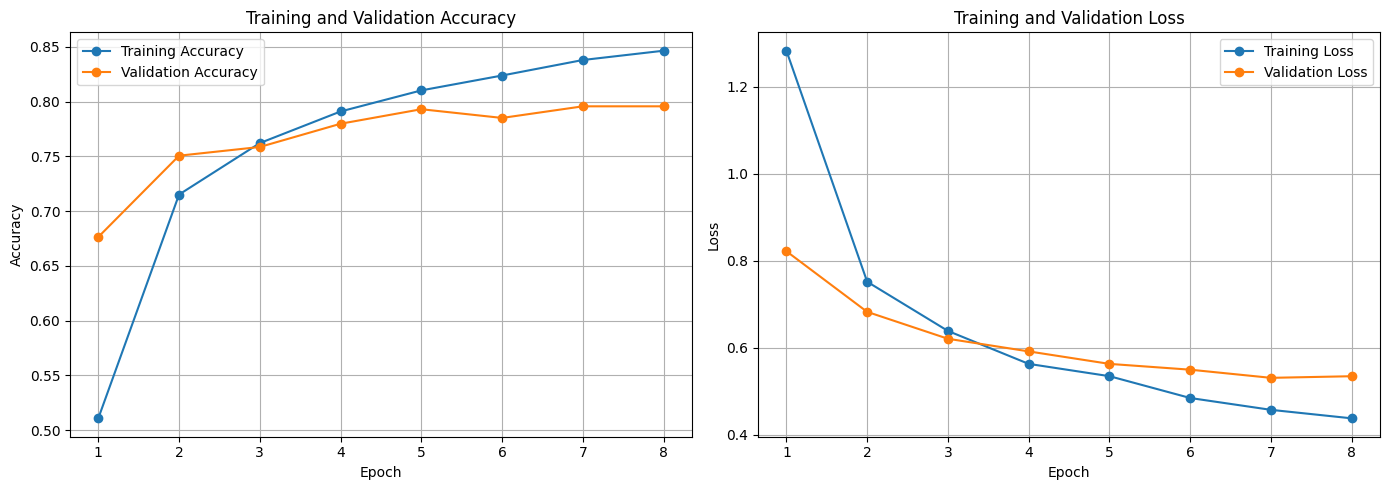

Best validation accuracy: 79.58%
Training graphs generated successfully!


In [ ]:

#cell 10

import matplotlib.pyplot as plt

if "history" not in globals():
    raise RuntimeError("Please run Cell 9 successfully before running Cell 10.")

acc = history.history.get("accuracy", [])
val_acc = history.history.get("val_accuracy", [])
loss = history.history.get("loss", [])
val_loss = history.history.get("val_loss", [])

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, marker="o", label="Training Accuracy")
plt.plot(epochs_range, val_acc, marker="o", label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, marker="o", label="Training Loss")
plt.plot(epochs_range, val_loss, marker="o", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("Best validation accuracy:", f"{max(val_acc) * 100:.2f}%")
print("Training graphs generated successfully!")


In [ ]:

#cell 11

import os
import tensorflow as tf

if not os.path.exists(BEST_MODEL_PATH):
    raise FileNotFoundError(
        "Best model file not found. Please run Cell 9 successfully first."
    )

best_model = tf.keras.models.load_model(BEST_MODEL_PATH)

print("Best model loaded successfully!")
print("Model name:", best_model.name)
print("Number of classes:", len(class_names))
print("Model input shape:", best_model.input_shape)
print("Model output shape:", best_model.output_shape)


Best model loaded successfully!
Model name: SmartWasteClassifier
Number of classes: 6
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 6)


In [ ]:

#cell 12

test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print("Number of waste categories:", len(class_names))
print("========================================")

if test_accuracy >= 0.90:
    print("Excellent! Test accuracy reached 90% or above.")
else:
    print("Test accuracy is below 90%. We can assess improvements.")


12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.8203 - loss: 0.4428

========== FINAL TEST RESULTS ==========
Test Accuracy: 82.03%
Test Loss: 0.4428
Number of waste categories: 6
Test accuracy is below 90%. We can assess improvements.


12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step
CLASSIFICATION REPORT

              precision    recall  f1-score   support

   cardboard      0.980     0.820     0.893        61
       glass      0.784     0.763     0.773        76
       metal      0.831     0.871     0.850        62
       paper      0.874     0.922     0.897        90
     plastic      0.782     0.836     0.808        73
       trash      0.714     0.682     0.698        22

    accuracy                          0.836       384
   macro avg      0.827     0.816     0.820       384
weighted avg      0.839     0.836     0.836       384



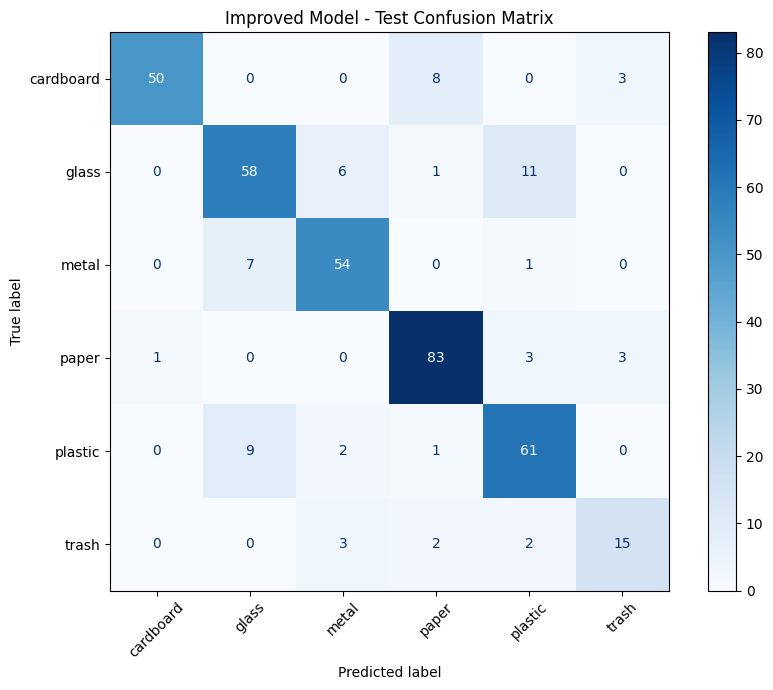

In [ ]:

#cell 13

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = improved_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("CLASSIFICATION REPORT\n")
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0,
    digits=3
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Improved Model - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

#cell 14

import tensorflow as tf
import os

# Find the pretrained MobileNetV2 model inside our classifier
base_model_ft = next(
    (
        layer for layer in best_model.layers
        if isinstance(layer, tf.keras.Model)
        and "mobilenetv2" in layer.name.lower()
    ),
    None
)

if base_model_ft is None:
    raise ValueError(
        "MobileNetV2 base model not found. Please check Cell 7."
    )

# Unfreeze only the final 30 layers
base_model_ft.trainable = True

for layer in base_model_ft.layers:
    layer.trainable = False

for layer in base_model_ft.layers[-30:]:
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

# Use a very small learning rate for fine-tuning
best_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

print("Starting fine-tuning...")
print(
    "Trainable MobileNetV2 layers:",
    sum(layer.trainable for layer in base_model_ft.layers)
)

fine_tune_history = best_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=fine_tune_callbacks,
    verbose=1
)

print("\nFine-tuning completed!")
print("Best model saved:", os.path.exists(BEST_MODEL_PATH))


Starting fine-tuning...
Trainable MobileNetV2 layers: 19
Epoch 1/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.8272 - loss: 0.4546
Epoch 1: val_accuracy improved from None to 0.80637, saving model to /content/smart_waste_models/best_smart_waste_model.keras

Epoch 1: finished saving model to /content/smart_waste_models/best_smart_waste_model.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 16s 119ms/step - accuracy: 0.8352 - loss: 0.4405 - val_accuracy: 0.8064 - val_loss: 0.5195 - learning_rate: 1.0000e-05
Epoch 2/5
55/56 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.8573 - loss: 0.4020
Epoch 2: val_accuracy improved from 0.80637 to 0.81167, saving model to /content/smart_waste_models/best_smart_waste_model.keras

Epoch 2: finished saving model to /content/smart_waste_models/best_smart_waste_model.keras

Epoch 2: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.8584 - loss: 0.3887 - val_accuracy: 0.8117 - val_loss: 0.5

In [ ]:

#cell 15

import os
import tensorflow as tf

if not os.path.exists(BEST_MODEL_PATH):
    raise FileNotFoundError(
        "Saved model not found. Please complete Cell 14 first."
    )

improved_model = tf.keras.models.load_model(BEST_MODEL_PATH)

test_loss, test_accuracy = improved_model.evaluate(
    test_ds,
    verbose=1
)

print("\n========== IMPROVED MODEL RESULTS ==========")
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Final Test Loss: {test_loss:.4f}")
print("============================================")


12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.8359 - loss: 0.4104

========== IMPROVED MODEL RESULTS ==========
Final Test Accuracy: 83.59%
Final Test Loss: 0.4104


In [ ]:

#cell 16

import os
import numpy as np
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

# Count training images in each category
class_counts = np.array([
    len([
        f for f in os.listdir(os.path.join(TRAIN_DIR, category))
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])
    for category in class_names
])

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=np.concatenate([
        labels.numpy() for _, labels in train_ds
    ])
)

class_weights = {
    i: float(weight)
    for i, weight in enumerate(class_weights_array)
}

print("Training images per category:")
for category, count in zip(class_names, class_counts):
    print(f"{category}: {count}")

print("\nClass weights:")
for i, category in enumerate(class_names):
    print(f"{category}: {class_weights[i]:.3f}")

# Keep the original model safe
WEIGHTED_MODEL_PATH = (
    "/content/smart_waste_models/weighted_waste_model.keras"
)

weighted_model = tf.keras.models.load_model(BEST_MODEL_PATH)

# Fine-tune the final MobileNetV2 layers
base_model_weighted = next(
    layer for layer in weighted_model.layers
    if isinstance(layer, tf.keras.Model)
    and "mobilenetv2" in layer.name.lower()
)

base_model_weighted.trainable = True

for layer in base_model_weighted.layers:
    layer.trainable = False

for layer in base_model_weighted.layers[-30:]:
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-6),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

weighted_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        WEIGHTED_MODEL_PATH,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    )
]

weighted_history = weighted_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weights,
    callbacks=weighted_callbacks,
    verbose=1
)

print("\nClass-weighted training completed!")
print("Saved separate model:", os.path.exists(WEIGHTED_MODEL_PATH))


Training images per category:
cardboard: 282
glass: 350
metal: 287
paper: 415
plastic: 337
trash: 95

Class weights:
cardboard: 1.044
glass: 0.841
metal: 1.026
paper: 0.709
plastic: 0.873
trash: 3.098
Epoch 1/5
55/56 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.8688 - loss: 0.4042
Epoch 1: val_accuracy improved from None to 0.81698, saving model to /content/smart_waste_models/weighted_waste_model.keras

Epoch 1: finished saving model to /content/smart_waste_models/weighted_waste_model.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 11s 111ms/step - accuracy: 0.8669 - loss: 0.3926 - val_accuracy: 0.8170 - val_loss: 0.4897
Epoch 2/5
55/56 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.8697 - loss: 0.3474
Epoch 2: val_accuracy did not improve from 0.81698
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.8681 - loss: 0.3564 - val_accuracy: 0.8170 - val_loss: 0.4847
Epoch 3/5
55/56 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.8601 - loss: 0.3706
Epoch 3: val_accuracy did not improve from 0.816

In [ ]:

#cell 17

import os
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report

if not os.path.exists(WEIGHTED_MODEL_PATH):
    raise FileNotFoundError(
        "Weighted model not found. Please run Cell 16 successfully."
    )

final_model = tf.keras.models.load_model(WEIGHTED_MODEL_PATH)

test_loss, test_accuracy = final_model.evaluate(
    test_ds,
    verbose=1
)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = final_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("\n========== FINAL MODEL RESULTS ==========")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0,
    digits=3
))

print("=========================================")


12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.8411 - loss: 0.3993
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step

========== FINAL MODEL RESULTS ==========
Test Accuracy: 84.11%
Test Loss: 0.3993

Classification Report:

              precision    recall  f1-score   support

   cardboard      0.962     0.820     0.885        61
       glass      0.824     0.737     0.778        76
       metal      0.821     0.887     0.853        62
       paper      0.874     0.922     0.897        90
     plastic      0.785     0.849     0.816        73
       trash      0.739     0.773     0.756        22

    accuracy                          0.841       384
   macro avg      0.834     0.831     0.831       384
weighted avg      0.845     0.841     0.841       384

